In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/healthcare_dataset.csv")

df.head()

,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


In [3]:
print("Rows and Columns:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nData Types:")
print(df.dtypes)

print("\nFirst 5 Records:")
display(df.head())

Rows and Columns: (55500, 15)

Column Names:
Index(['Name', 'Age', 'Gender', 'Blood Type', 'Medical Condition',
       'Date of Admission', 'Doctor', 'Hospital', 'Insurance Provider',
       'Billing Amount', 'Room Number', 'Admission Type', 'Discharge Date',
       'Medication', 'Test Results'],
      dtype='object')

Data Types:
Name                   object
Age                     int64
Gender                 object
Blood Type             object
Medical Condition      object
Date of Admission      object
Doctor                 object
Hospital               object
Insurance Provider     object
Billing Amount        float64
Room Number             int64
Admission Type         object
Discharge Date         object
Medication             object
Test Results           object
dtype: object

First 5 Records:


,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal


In [4]:
print(df.isnull().sum())

Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           0
Admission Type        0
Discharge Date        0
Medication            0
Test Results          0
dtype: int64


In [5]:
categorical_columns = df.select_dtypes(include='object').columns

for col in categorical_columns:
    df[col] = df[col].fillna('Unknown')
numerical_columns = df.select_dtypes(include=np.number).columns

for col in numerical_columns:
    df[col] = df[col].fillna(df[col].median())

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           0
Admission Type        0
Discharge Date        0
Medication            0
Test Results          0
dtype: int64


In [6]:
df['Medical Condition'] = df['Medical Condition'].str.strip().str.title()

print(df['Medical Condition'].value_counts())

Medical Condition
Arthritis       9308
Diabetes        9304
Hypertension    9245
Obesity         9231
Cancer          9227
Asthma          9185
Name: count, dtype: int64


In [7]:
df['Date of Admission'] = pd.to_datetime(
    df['Date of Admission'],
    errors='coerce'
)

df['Discharge Date'] = pd.to_datetime(
    df['Discharge Date'],
    errors='coerce'
)

print(df[['Date of Admission', 'Discharge Date']].head())

  Date of Admission Discharge Date
0        2024-01-31     2024-02-02
1        2019-08-20     2019-08-26
2        2022-09-22     2022-10-07
3        2020-11-18     2020-12-18
4        2022-09-19     2022-10-09


In [8]:
df['Hospital Stay Days'] = (
    df['Discharge Date'] - df['Date of Admission']
).dt.days

print(df[['Date of Admission', 'Discharge Date', 'Hospital Stay Days']].head())

  Date of Admission Discharge Date  Hospital Stay Days
0        2024-01-31     2024-02-02                   2
1        2019-08-20     2019-08-26                   6
2        2022-09-22     2022-10-07                  15
3        2020-11-18     2020-12-18                  30
4        2022-09-19     2022-10-09                  20


In [9]:
df.loc[df['Hospital Stay Days'] < 0, 'Hospital Stay Days'] = np.nan

df['Hospital Stay Days'] = df['Hospital Stay Days'].fillna(
    df['Hospital Stay Days'].median()
)

print(df['Hospital Stay Days'].describe())

count    55500.000000
mean        15.509009
std          8.659600
min          1.000000
25%          8.000000
50%         15.000000
75%         23.000000
max         30.000000
Name: Hospital Stay Days, dtype: float64


In [10]:
df['Admission Type'] = df['Admission Type'].str.strip().str.title()

df['Urgency Category'] = df['Admission Type'].replace({
    'Emergency': 'Emergency',
    'Elective': 'Elective',
    'Urgent': 'Urgent'
})

print(df['Urgency Category'].value_counts())

Urgency Category
Elective     18655
Urgent       18576
Emergency    18269
Name: count, dtype: int64


In [11]:
demographic_summary = df.groupby('Medical Condition').agg(
    Patient_Count=('Name', 'count'),
    Average_Age=('Age', 'mean'),
    Male_Count=('Gender', lambda x: (x == 'Male').sum()),
    Female_Count=('Gender', lambda x: (x == 'Female').sum())
).reset_index()

display(demographic_summary)

,Medical Condition,Patient_Count,Average_Age,Male_Count,Female_Count
0,Arthritis,9308,51.565320,4622,4686
1,Asthma,9185,51.575830,4632,4553
2,Cancer,9227,51.558795,4625,4602
3,Diabetes,9304,51.554170,4653,4651
4,Hypertension,9245,51.741915,4633,4612
5,Obesity,9231,51.240277,4609,4622


Medical Condition
Arthritis       9308
Diabetes        9304
Hypertension    9245
Obesity         9231
Cancer          9227
Asthma          9185
Name: count, dtype: int64


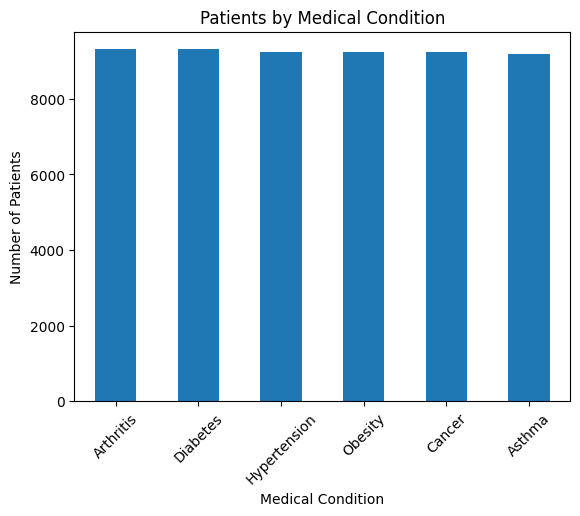

In [12]:
condition_count = df['Medical Condition'].value_counts()

print(condition_count)

condition_count.plot(kind='bar')

plt.title('Patients by Medical Condition')
plt.xlabel('Medical Condition')
plt.ylabel('Number of Patients')
plt.xticks(rotation=45)
plt.show()

Urgency Category
Elective     18655
Urgent       18576
Emergency    18269
Name: count, dtype: int64


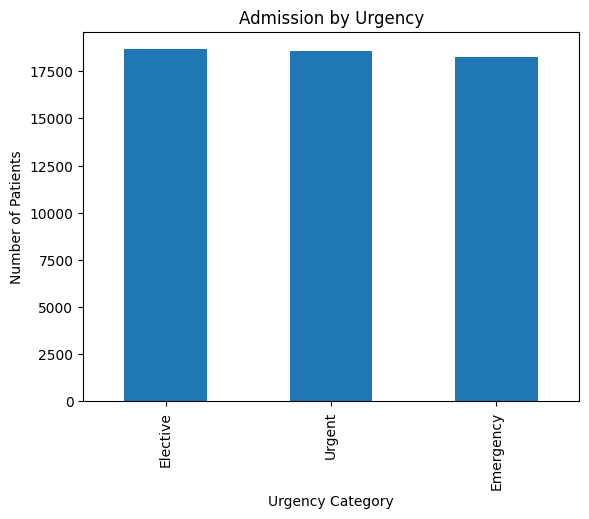

In [13]:
admission_count = df['Urgency Category'].value_counts()

print(admission_count)

admission_count.plot(kind='bar')

plt.title('Admission by Urgency')
plt.xlabel('Urgency Category')
plt.ylabel('Number of Patients')
plt.show()

In [14]:
billing_stats = df['Billing Amount'].describe()

print("Billing Amount Statistics:")
print(billing_stats)

Billing Amount Statistics:
count    55500.000000
mean     25539.316097
std      14211.454431
min      -2008.492140
25%      13241.224652
50%      25538.069376
75%      37820.508436
max      52764.276736
Name: Billing Amount, dtype: float64


In [15]:
stay_stats = df['Hospital Stay Days'].describe()

print("Hospital Stay Statistics:")
print(stay_stats)

Hospital Stay Statistics:
count    55500.000000
mean        15.509009
std          8.659600
min          1.000000
25%          8.000000
50%         15.000000
75%         23.000000
max         30.000000
Name: Hospital Stay Days, dtype: float64


In [16]:
condition_analysis = df.groupby('Medical Condition').agg(
    Average_Billing=('Billing Amount', 'mean'),
    Total_Billing=('Billing Amount', 'sum'),
    Average_Stay=('Hospital Stay Days', 'mean'),
    Maximum_Stay=('Hospital Stay Days', 'max')
).reset_index()

display(condition_analysis)

,Medical Condition,Average_Billing,Total_Billing,Average_Stay,Maximum_Stay
0,Arthritis,25497.327056,2.373291e+08,15.517404,30.0
1,Asthma,25635.249359,2.354598e+08,15.696570,30.0
2,Cancer,25161.792707,2.321679e+08,15.495827,30.0
3,Diabetes,25638.405577,2.385397e+08,15.422936,30.0
4,Hypertension,25497.095761,2.357207e+08,15.458626,30.0
5,Obesity,25805.971259,2.382149e+08,15.464305,30.0


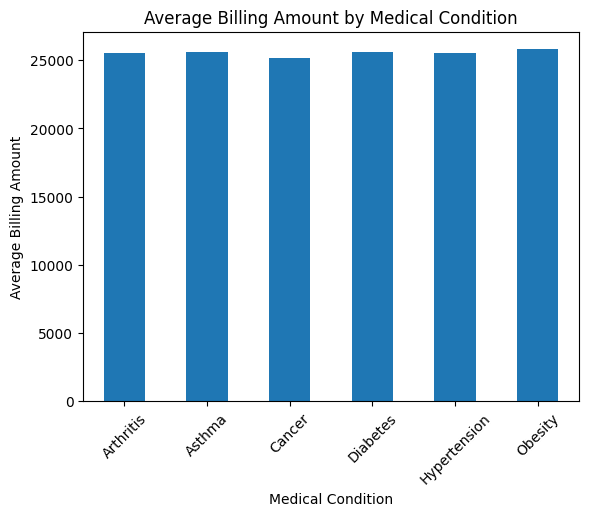

In [17]:
df.groupby('Medical Condition')['Billing Amount'].mean().plot(
    kind='bar'
)

plt.title('Average Billing Amount by Medical Condition')
plt.xlabel('Medical Condition')
plt.ylabel('Average Billing Amount')
plt.xticks(rotation=45)
plt.show()

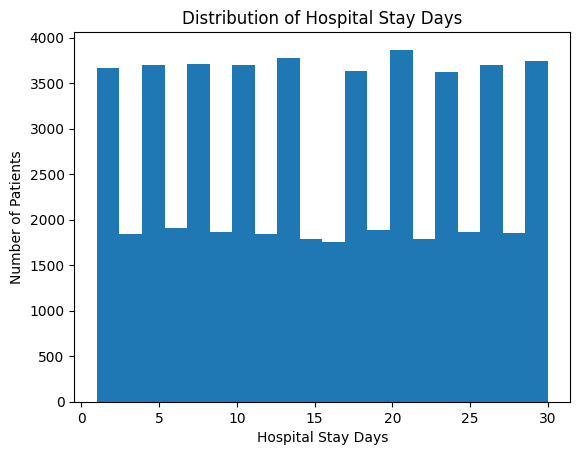

In [18]:
plt.hist(df['Hospital Stay Days'], bins=20)

plt.title('Distribution of Hospital Stay Days')
plt.xlabel('Hospital Stay Days')
plt.ylabel('Number of Patients')
plt.show()

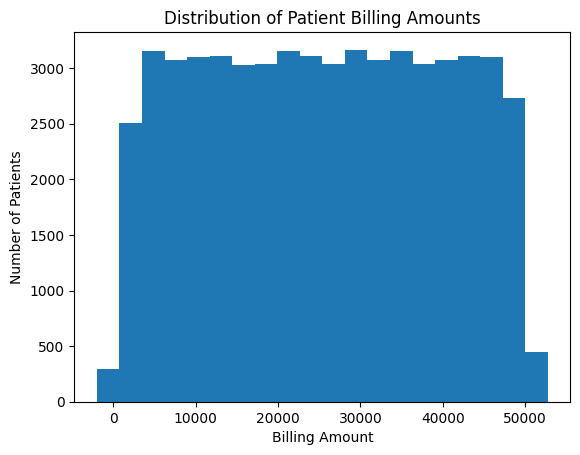

In [19]:
plt.hist(df['Billing Amount'], bins=20)

plt.title('Distribution of Patient Billing Amounts')
plt.xlabel('Billing Amount')
plt.ylabel('Number of Patients')
plt.show()

Gender,Female,Male
Medical Condition,,
Arthritis,4686,4622
Asthma,4553,4632
Cancer,4602,4625
Diabetes,4651,4653
Hypertension,4612,4633
Obesity,4622,4609


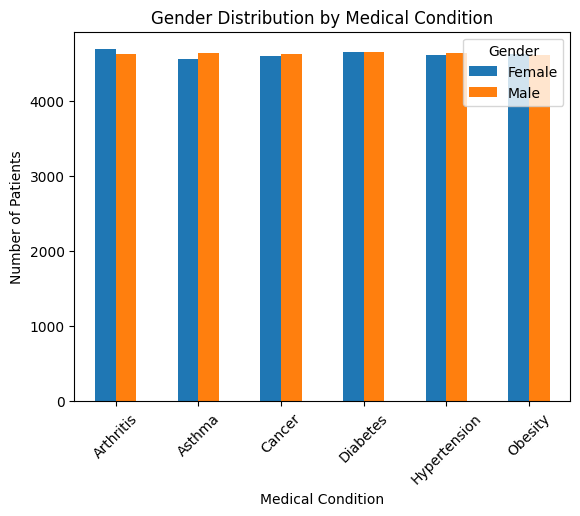

In [20]:
gender_condition = pd.crosstab(
    df['Medical Condition'],
    df['Gender']
)

display(gender_condition)

gender_condition.plot(kind='bar')

plt.title('Gender Distribution by Medical Condition')
plt.xlabel('Medical Condition')
plt.ylabel('Number of Patients')
plt.xticks(rotation=45)
plt.show()

In [21]:
print("Final Dataset Shape:", df.shape)

print("\nRemaining Missing Values:")
print(df.isnull().sum())

display(df.head())

Final Dataset Shape: (55500, 17)

Remaining Missing Values:
Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           0
Admission Type        0
Discharge Date        0
Medication            0
Test Results          0
Hospital Stay Days    0
Urgency Category      0
dtype: int64


,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results,Hospital Stay Days,Urgency Category
0,Bobby JacksOn,30,Male,B-,Cancer,2024-01-31,Matthew Smith,Sons and Miller,Blue Cross,18856.281306,328,Urgent,2024-02-02,Paracetamol,Normal,2.0,Urgent
1,LesLie TErRy,62,Male,A+,Obesity,2019-08-20,Samantha Davies,Kim Inc,Medicare,33643.327287,265,Emergency,2019-08-26,Ibuprofen,Inconclusive,6.0,Emergency
2,DaNnY sMitH,76,Female,A-,Obesity,2022-09-22,Tiffany Mitchell,Cook PLC,Aetna,27955.096079,205,Emergency,2022-10-07,Aspirin,Normal,15.0,Emergency
3,andrEw waTtS,28,Female,O+,Diabetes,2020-11-18,Kevin Wells,"Hernandez Rogers and Vang,",Medicare,37909.782410,450,Elective,2020-12-18,Ibuprofen,Abnormal,30.0,Elective
4,adrIENNE bEll,43,Female,AB+,Cancer,2022-09-19,Kathleen Hanna,White-White,Aetna,14238.317814,458,Urgent,2022-10-09,Penicillin,Abnormal,20.0,Urgent


In [22]:
df.to_csv('cleaned_healthcare_dataset.csv', index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
